# Training Dynamics

Compare selected DFST, RNN and GRU histories for add2 and mult2 at one million training iterations. The notebook produces four **1 × 2 figures**, one for each combination of add2 or mult2 and ULG or RLG. Each figure shows averaged training loss on the left and the selected metric at 100k-iteration checkpoints on the right. Omitted models contribute no curves or legend entries.

The notebook reads saved histories without querying W&B, training models or evaluating checkpoints. Install `pip install -e '.[analysis]'` from the repository root and select that environment in Jupyter.


In [5]:
from pathlib import Path
import json
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(os.environ["DEL_REPO_ROOT"]) if os.environ.get("DEL_REPO_ROOT") else next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/differentiable_exact_learning").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from differentiable_exact_learning.analysis.training_dynamics import (
    MODELS, MODEL_COLORS, load_history, plot_training_dynamics,
)
from differentiable_exact_learning.analysis.plot_style import apply_paper_style
from differentiable_exact_learning.analysis.paper_heatmaps import save_figure, figure_output_dir
apply_paper_style()

def repo_path(value):
    path = Path(value).expanduser()
    return path if path.is_absolute() else ROOT / path


## 1. Select Runs

The `training_dynamics` section in `paper/figures.yaml` selects the 1M-step histories under `analyses/training_dynamics/`. The settings cell loads those selections into `RUNS`. Add baseline paths in `RUNS` as needed. Leave `None` to omit a model from a comparison. A supplied path must exist and contain valid artifacts; an invalid path raises an error. Each task requires at least one selected model. Model selection remains explicit and independent of final ULG.

Supply an absolute path or a repository-relative directory containing `config.yaml`, `metrics.jsonl` and checkpoint evaluations. Each selected run must match the task, architecture and one-million-step budget. Training curves require the saved loss log and checkpoint evaluations. Portable histories follow `analyses/training_dynamics/<model>/<task>/`.

The loader reads `evaluation_*.json`, `evaluation.json` and `evaluations/step_*.json` within each selected run. To use another evaluation directory, set the corresponding `EVALUATION_DIRS` entry. The override replaces the default sources and must contain all ten checkpoint evaluations. Each JSON follows the DEL evaluation format, with `step`, the evaluation protocol and both `ulg` and `rlg` under `tasks.addition2` or `tasks.multiplication2`.

`LOSS_WINDOW` measures training iterations. Each logged loss represents the mean since the preceding entry; the trailing average weights intervals by duration. The initial window uses only observed iterations. With logs every 100 updates, a 1,000-iteration window averages ten complete rows. The average smooths recorded training loss without introducing a held-out measurement.


In [6]:
import yaml

SELECTIONS = yaml.safe_load((ROOT / "paper/figures.yaml").read_text())["training_dynamics"]
EXPERIMENTS = {name: {key: spec[key] for key in ("task", "steps")} for name, spec in SELECTIONS.items()}
RUNS = {name: dict(spec["runs"]) for name, spec in SELECTIONS.items()}
# Override a model here, or edit training_dynamics in paper/figures.yaml.
# RUNS["add2_1M"]["RNN"] = "analyses/training_dynamics/RNN/add2"
EVALUATION_DIRS = {
    name: {model: None for model in MODELS} for name in EXPERIMENTS
}
# Replace baseline selections above, or assign a specific comparison below:
LOSS_WINDOW = 1000
EVALUATION_EVERY = 100000
OUTPUT_DIR = figure_output_dir(ROOT, "training_dynamics")


## 2. Load Histories and Evaluation Protocols

Selected histories require loss observations through one million iterations and ULG/RLG evaluations at every 100k-step checkpoint. Conflicting duplicate evaluations, incomplete histories and inconsistent metric protocols raise errors. The protocol table documents the measurements used by each curve.

ULG measures exact agreement on random operand pairs, so its table rows show `Not applicable (ULG)` under `hard_cases`. RLG evaluates additional structured cases and reports the selected hard-case family. Measured zeros remain visible. A cap annotation identifies the tested ceiling; ordinary point markers show all observations without additional ceiling symbols. Zero averaged losses remain in the CSV but create gaps on the logarithmic loss axis.


In [7]:
histories = {metric: {} for metric in ("ulg", "rlg")}
protocols = []
for metric in histories:
    for name, selections in RUNS.items():
        task = EXPERIMENTS[name]["task"]
        histories[metric][task] = {}
        for model in MODELS:
            selected = selections[model]
            if selected is None:
                continue
            evaluation_dir = EVALUATION_DIRS[name][model]
            history = load_history(
                repo_path(selected), model=model, task=task, loss_window=LOSS_WINDOW,
                evaluation_every=EVALUATION_EVERY, metric=metric,
                evaluation_dir=repo_path(evaluation_dir) if evaluation_dir is not None else None,
            )
            if history["planned_steps"] != EXPERIMENTS[name]["steps"]:
                raise ValueError(f"{name} / {model}: select a run trained with the matching total budget")
            histories[metric][task][model] = history
            if history["protocol"] is not None:
                protocols.append(dict(comparison=name, task=task, model=model, metric=metric, **history["protocol"]))
if protocols:
    protocol_table = pd.DataFrame(protocols)
    protocol_table.loc[protocol_table["metric"] == "ulg", "hard_cases"] = "Not applicable (ULG)"
    display(protocol_table)


,comparison,task,model,metric,protocol,seed,samples,cap,search,scan,hard_cases
0,add2_1M,add2,DFST,ulg,teacher_forced_exact_match,42,10,5000,binary,parallel,Not applicable (ULG)
1,add2_1M,add2,RNN,ulg,teacher_forced_exact_match,42,10,5000,binary,parallel,Not applicable (ULG)
2,add2_1M,add2,GRU,ulg,teacher_forced_exact_match,42,10,5000,binary,parallel,Not applicable (ULG)
3,mult2_1M,mult2,DFST,ulg,teacher_forced_exact_match,42,10,1000,binary,parallel,Not applicable (ULG)
4,mult2_1M,mult2,RNN,ulg,teacher_forced_exact_match,42,10,1000,binary,parallel,Not applicable (ULG)
5,mult2_1M,mult2,GRU,ulg,teacher_forced_exact_match,42,10,1000,binary,parallel,Not applicable (ULG)
6,add2_1M,add2,DFST,rlg,teacher_forced_exact_match,42,10,5000,binary,parallel,all
7,add2_1M,add2,RNN,rlg,teacher_forced_exact_match,42,10,5000,binary,parallel,all
8,add2_1M,add2,GRU,rlg,teacher_forced_exact_match,42,10,5000,binary,parallel,all
9,mult2_1M,mult2,DFST,rlg,teacher_forced_exact_match,42,10,1000,binary,parallel,all


## 3. Export Figures and Curve Data

The figures use the shared paper palette, serif fonts, gray panels and curve styling. DFST uses terracotta, RNN blue, GRU ochre. The colors remain fixed when models change. Each legend lists only the selected models. Generalization markers show measured checkpoints; connecting segments guide the eye.

Exports include PDF, SVG and 300-DPI PNG figures, the plotted loss and metric tables, and settings identifying every selected run. The four figures use `training_dynamics_<task>_<metric>_1M` under `analysis_outputs/paper_figures/training_dynamics/`, with `task` set to `add2` or `mult2` and `metric` set to `ulg` or `rlg`. Curve tables include a task column. Repeated exports replace matching filenames. `DEL_ANALYSIS_DIR` selects another figure root while preserving these subfolders.


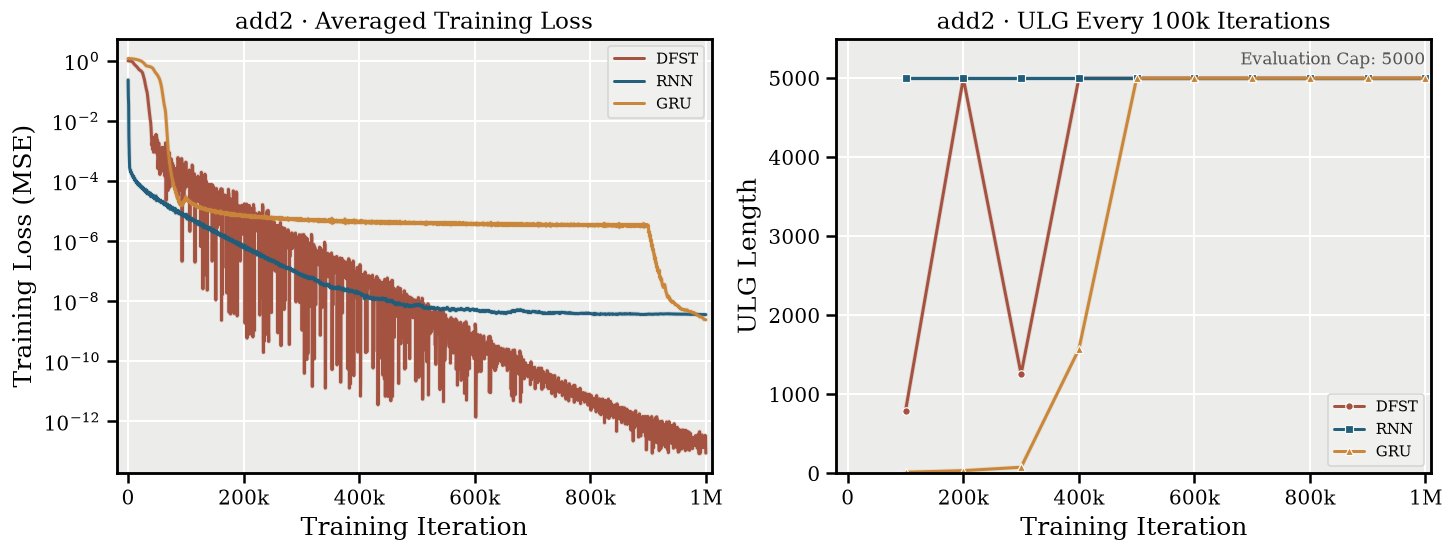

{'pdf': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_add2_ulg_1M.pdf'), 'svg': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_add2_ulg_1M.svg'), 'png': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_add2_ulg_1M.png')}


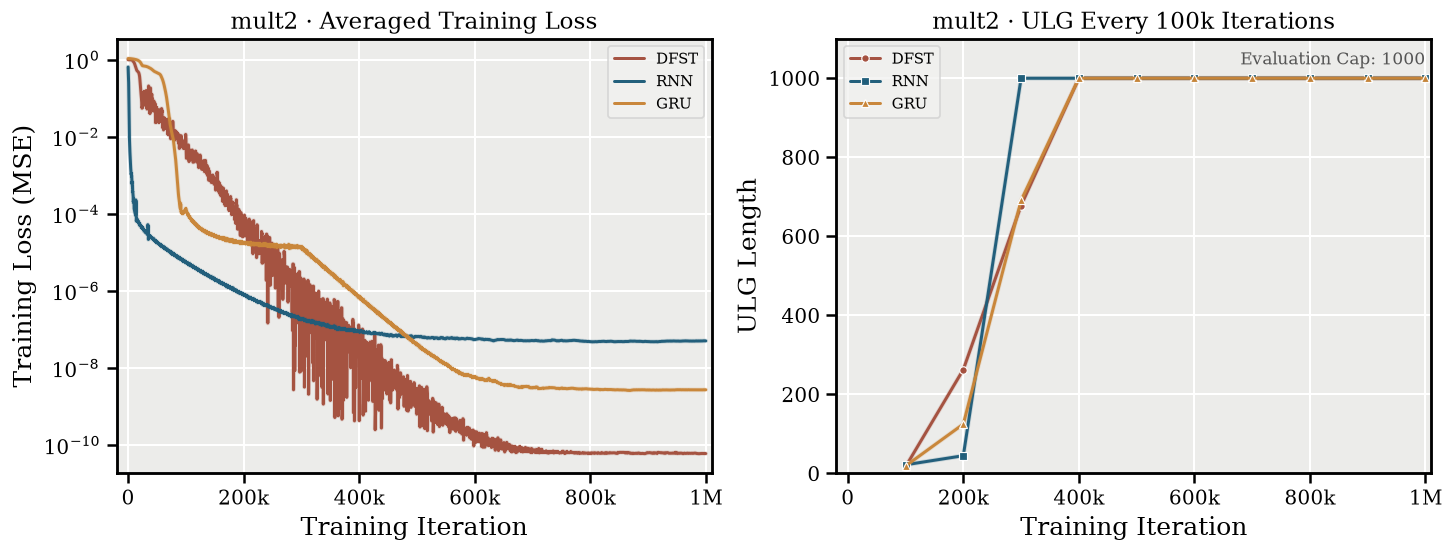

{'pdf': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_mult2_ulg_1M.pdf'), 'svg': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_mult2_ulg_1M.svg'), 'png': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_mult2_ulg_1M.png')}


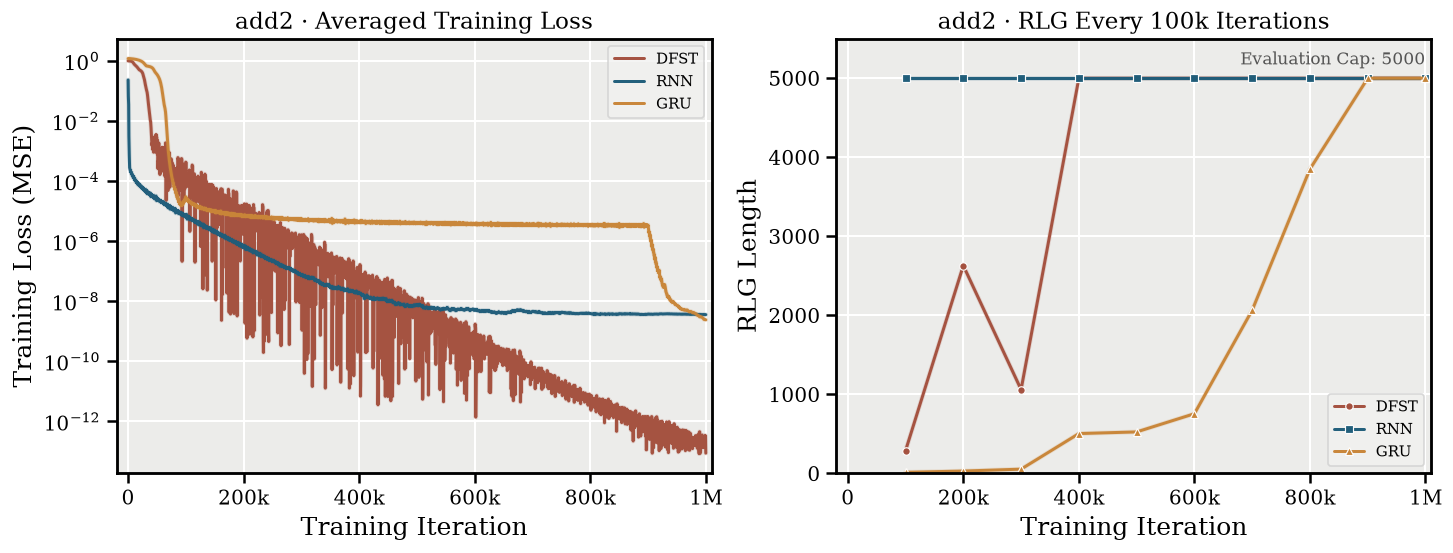

{'pdf': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_add2_rlg_1M.pdf'), 'svg': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_add2_rlg_1M.svg'), 'png': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_add2_rlg_1M.png')}


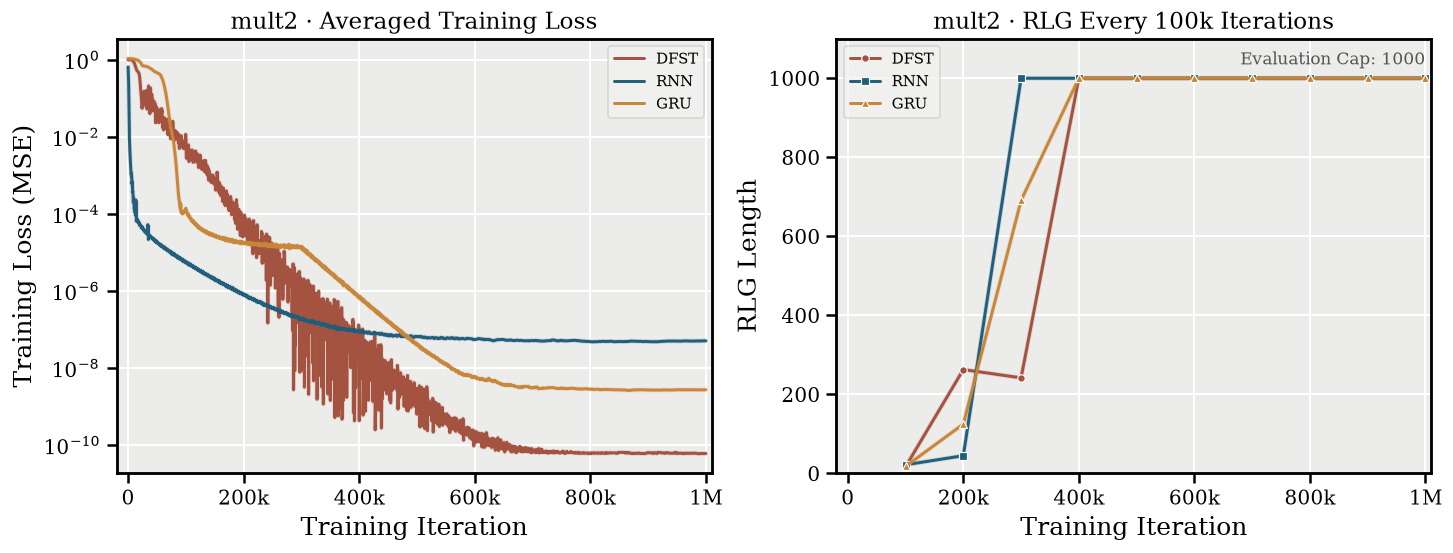

{'pdf': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_mult2_rlg_1M.pdf'), 'svg': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_mult2_rlg_1M.svg'), 'png': PosixPath('/tmlscratch/hpapazov/DEL/analysis_outputs/paper_figures/training_dynamics/training_dynamics_mult2_rlg_1M.png')}


In [8]:
for metric, tasks in histories.items():
    for task, selected in tasks.items():
        if not selected:
            print(f"{task} / {metric.upper()}: select at least one run to export this figure.")
            continue
        fig = plot_training_dynamics(selected, task, metric=metric)
        prefix = OUTPUT_DIR / f"training_dynamics_{task}_{metric}_1M"
        paths = save_figure(fig, prefix)
        display(fig)
        plt.close(fig)
        for table_name in ("loss", metric):
            table = pd.concat([
                history[table_name].assign(task=task, model=model, run=history["run"])
                for model, history in selected.items()
            ], ignore_index=True)
            table.to_csv(prefix.with_name(prefix.name + f"_{table_name}.csv"), index=False)
        settings = dict(
            task=task, metric=metric, loss_window=LOSS_WINDOW,
            evaluation_every=EVALUATION_EVERY,
            runs={model: history["run"] for model, history in selected.items()},
            protocols={model: history["protocol"] for model, history in selected.items()},
            colors=MODEL_COLORS,
        )
        prefix.with_name(prefix.name + "_settings.json").write_text(json.dumps(settings, indent=2) + "\n")
        print(paths)
